In [1]:
# ==========================================
# =                 SETUP                  =
# ==========================================
import sys
import os
import torch
import torch.optim as optim
import matplotlib.pyplot as plt

if os.path.abspath('..') not in sys.path:
    sys.path.append(os.path.abspath('..'))

from src.dataset import get_data_splits, get_dataloaders
from src.augmentation import (
    get_train_transform_baseline, get_valid_transform,
    get_train_transform_geo, get_valid_transform_clahe,
    get_train_transform_color_geo, get_train_transform_occlusion,
    get_train_transform_randaug
)
from src.models import get_resnet18_modified, get_efficientnet_b0_modified, get_cct_model
from src.losses import FocalLoss
from src.train import train_model, train_mixup_epoch, validate_one_epoch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo Ativo: {device}")

TRAIN_DIR = "../data/GTSRB/Training"
train_df, val_df = get_data_splits(TRAIN_DIR)
criterion = FocalLoss(gamma=2.0)
NUM_EPOCHS = 15

os.makedirs('../checkpoints', exist_ok=True)
history_all = {} 

Dispositivo Ativo: cuda


In [ ]:
# ==========================================
# =     MODELO 1 - BASELINE (ResNet18)     =
# ==========================================
print("\n" + "="*50)
print("A INICIAR MODELO 1: BASELINE")
print("="*50)
torch.cuda.empty_cache()

train_loader, val_loader = get_dataloaders(
    train_df, val_df, train_transform=get_train_transform_baseline(), val_transform=get_valid_transform(), batch_size=64
)
model1 = get_resnet18_modified(num_classes=43, pretrained=True).to(device)
opt1 = optim.AdamW(model1.parameters(), lr=0.001, weight_decay=1e-4)
sch1 = optim.lr_scheduler.CosineAnnealingLR(opt1, T_max=NUM_EPOCHS)

history_all['M1_Baseline'] = train_model(
    model1, train_loader, val_loader, criterion, opt1, sch1, device, NUM_EPOCHS, "modelo1_baseline_resnet18"
)


A INICIAR MODELO 1: BASELINE


Epoch 1/15 | Train Loss: 0.1615 | Train Acc: 93.47% | Val Loss: 0.0204 | Val Acc: 98.79%
-> Melhor modelo guardado! (Accuracy: 98.79%)


Epoch 2/15 | Train Loss: 0.0234 | Train Acc: 98.70% | Val Loss: 0.1299 | Val Acc: 95.21%


Epoch 3/15 | Train Loss: 0.0145 | Train Acc: 99.20% | Val Loss: 0.0073 | Val Acc: 99.60%
-> Melhor modelo guardado! (Accuracy: 99.60%)


Epoch 4/15 | Train Loss: 0.0059 | Train Acc: 99.62% | Val Loss: 0.0176 | Val Acc: 98.74%


Epoch 5/15 | Train Loss: 0.0075 | Train Acc: 99.55% | Val Loss: 0.0127 | Val Acc: 99.30%


... (6 outputs left out)

Epoch 12/15 | Train Loss: 0.0000 | Train Acc: 100.00% | Val Loss: 0.0012 | Val Acc: 99.94%


Epoch 13/15 | Train Loss: 0.0000 | Train Acc: 100.00% | Val Loss: 0.0010 | Val Acc: 99.96%


Epoch 14/15 | Train Loss: 0.0000 | Train Acc: 100.00% | Val Loss: 0.0010 | Val Acc: 99.94%


Epoch 15/15 | Train Loss: 0.0000 | Train Acc: 100.00% | Val Loss: 0.0010 | Val Acc: 99.96%


In [ ]:
# ==========================================
# =     MODELO 2 - GEO + CLAHE (ResNet18)  =
# ==========================================
print("\n" + "="*50)
print("A INICIAR MODELO 2: GEO + CLAHE")
print("="*50)
torch.cuda.empty_cache()

train_loader, val_loader = get_dataloaders(
    train_df, val_df, train_transform=get_train_transform_geo(), val_transform=get_valid_transform_clahe(), batch_size=64
)
model2 = get_resnet18_modified(num_classes=43, pretrained=True).to(device)
opt2 = optim.AdamW(model2.parameters(), lr=0.001, weight_decay=1e-4)
sch2 = optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=NUM_EPOCHS)

history_all['M2_Geo'] = train_model(
    model2, train_loader, val_loader, criterion, opt2, sch2, device, NUM_EPOCHS, "modelo2_geo_resnet18"
)

/home/ruirodrigues/Documents/Visão /venv/lib/python3.12/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)



A INICIAR MODELO 2: GEO + CLAHE


Epoch 1/15 | Train Loss: 0.1488 | Train Acc: 93.34% | Val Loss: 0.0296 | Val Acc: 98.21%
-> Melhor modelo guardado! (Accuracy: 98.21%)


Epoch 2/15 | Train Loss: 0.0332 | Train Acc: 98.03% | Val Loss: 0.0097 | Val Acc: 99.45%
-> Melhor modelo guardado! (Accuracy: 99.45%)


Epoch 3/15 | Train Loss: 0.0184 | Train Acc: 98.84% | Val Loss: 0.0153 | Val Acc: 99.32%


Epoch 4/15 | Train Loss: 0.0200 | Train Acc: 98.82% | Val Loss: 0.0096 | Val Acc: 99.42%


... (7 outputs left out)

Epoch 12/15 | Train Loss: 0.0006 | Train Acc: 99.98% | Val Loss: 0.0016 | Val Acc: 99.92%
-> Melhor modelo guardado! (Accuracy: 99.92%)


Epoch 13/15 | Train Loss: 0.0002 | Train Acc: 99.99% | Val Loss: 0.0013 | Val Acc: 99.94%
-> Melhor modelo guardado! (Accuracy: 99.94%)


Epoch 14/15 | Train Loss: 0.0002 | Train Acc: 99.99% | Val Loss: 0.0013 | Val Acc: 99.94%


Epoch 15/15 | Train Loss: 0.0001 | Train Acc: 99.99% | Val Loss: 0.0012 | Val Acc: 99.94%


In [ ]:
# ==========================================
# =      MODELO 3 - COR + GEO (ResNet18)   =
# ==========================================
print("\n" + "="*50)
print("A INICIAR MODELO 3: COR + GEO")
print("="*50)
torch.cuda.empty_cache()

train_loader, val_loader = get_dataloaders(
    train_df, val_df, train_transform=get_train_transform_color_geo(), val_transform=get_valid_transform_clahe(), batch_size=64
)
model3 = get_resnet18_modified(num_classes=43, pretrained=True).to(device)
opt3 = optim.AdamW(model3.parameters(), lr=0.001, weight_decay=1e-4)
sch3 = optim.lr_scheduler.CosineAnnealingLR(opt3, T_max=NUM_EPOCHS)

history_all['M3_CorGeo'] = train_model(
    model3, train_loader, val_loader, criterion, opt3, sch3, device, NUM_EPOCHS, "modelo3_cor_geo_resnet18"
)

/home/ruirodrigues/Documents/Visão /src/augmentation.py:80: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 50.0), p=0.2),



A INICIAR MODELO 3: COR + GEO


Epoch 1/15 | Train Loss: 0.2548 | Train Acc: 89.36% | Val Loss: 0.0444 | Val Acc: 97.49%
-> Melhor modelo guardado! (Accuracy: 97.49%)


Epoch 2/15 | Train Loss: 0.0712 | Train Acc: 96.14% | Val Loss: 0.0519 | Val Acc: 98.02%
-> Melhor modelo guardado! (Accuracy: 98.02%)


Epoch 3/15 | Train Loss: 0.0554 | Train Acc: 97.06% | Val Loss: 0.0219 | Val Acc: 98.04%
-> Melhor modelo guardado! (Accuracy: 98.04%)


Epoch 4/15 | Train Loss: 0.0396 | Train Acc: 97.87% | Val Loss: 0.0112 | Val Acc: 99.32%
-> Melhor modelo guardado! (Accuracy: 99.32%)


... (7 outputs left out)

Epoch 12/15 | Train Loss: 0.0106 | Train Acc: 99.38% | Val Loss: 0.0010 | Val Acc: 99.89%


Epoch 13/15 | Train Loss: 0.0095 | Train Acc: 99.45% | Val Loss: 0.0005 | Val Acc: 99.94%
-> Melhor modelo guardado! (Accuracy: 99.94%)


Epoch 14/15 | Train Loss: 0.0088 | Train Acc: 99.50% | Val Loss: 0.0004 | Val Acc: 99.96%
-> Melhor modelo guardado! (Accuracy: 99.96%)


Epoch 15/15 | Train Loss: 0.0076 | Train Acc: 99.59% | Val Loss: 0.0004 | Val Acc: 99.96%


In [ ]:
# ==========================================
# =   MODELO 4 - OCLUSÃO (EfficientNetB0)  =
# ==========================================
print("\n" + "="*50)
print("A INICIAR MODELO 4: OCLUSÃO (EfficientNet)")
print("="*50)
torch.cuda.empty_cache()

train_loader, val_loader = get_dataloaders(
    train_df, val_df, train_transform=get_train_transform_occlusion(), val_transform=get_valid_transform_clahe(), batch_size=64
)
model4 = get_efficientnet_b0_modified(num_classes=43, pretrained=True).to(device)
opt4 = optim.AdamW(model4.parameters(), lr=0.001, weight_decay=1e-4)
sch4 = optim.lr_scheduler.CosineAnnealingLR(opt4, T_max=NUM_EPOCHS)

history_all['M4_Oclusao'] = train_model(
    model4, train_loader, val_loader, criterion, opt4, sch4, device, NUM_EPOCHS, "modelo4_oclusao_efficientnet"
)

/home/ruirodrigues/Documents/Visão /src/augmentation.py:91: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, min_height, min_width, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=2, max_height=12, max_width=12, min_holes=1, min_height=8, min_width=8, fill_value=0, p=0.5),



A INICIAR MODELO 4: OCLUSÃO (EfficientNet)


Epoch 1/15 | Train Loss: 0.3283 | Train Acc: 85.87% | Val Loss: 0.0216 | Val Acc: 98.34%
-> Melhor modelo guardado! (Accuracy: 98.34%)


Epoch 2/15 | Train Loss: 0.0562 | Train Acc: 96.59% | Val Loss: 0.0257 | Val Acc: 98.30%


Epoch 3/15 | Train Loss: 0.0393 | Train Acc: 97.58% | Val Loss: 0.0182 | Val Acc: 98.77%
-> Melhor modelo guardado! (Accuracy: 98.77%)


Epoch 4/15 | Train Loss: 0.0306 | Train Acc: 98.05% | Val Loss: 0.0117 | Val Acc: 99.23%
-> Melhor modelo guardado! (Accuracy: 99.23%)


... (7 outputs left out)

Epoch 12/15 | Train Loss: 0.0030 | Train Acc: 99.76% | Val Loss: 0.0008 | Val Acc: 99.96%
-> Melhor modelo guardado! (Accuracy: 99.96%)


Epoch 13/15 | Train Loss: 0.0026 | Train Acc: 99.81% | Val Loss: 0.0009 | Val Acc: 99.98%
-> Melhor modelo guardado! (Accuracy: 99.98%)


Epoch 14/15 | Train Loss: 0.0021 | Train Acc: 99.86% | Val Loss: 0.0008 | Val Acc: 99.96%


Epoch 15/15 | Train Loss: 0.0022 | Train Acc: 99.83% | Val Loss: 0.0008 | Val Acc: 99.98%


In [ ]:
# ===============================================
# = MODELO 5 - RANDAUG + MIXUP (EfficientNetB0) =
# ===============================================
print("\n" + "="*50)
print("A INICIAR MODELO 5: RANDAUG + MIXUP")
print("="*50)
torch.cuda.empty_cache()

train_loader, val_loader = get_dataloaders(
    train_df, val_df, train_transform=get_train_transform_randaug(), val_transform=get_valid_transform_clahe(), batch_size=64
)
model5 = get_efficientnet_b0_modified(num_classes=43, pretrained=True).to(device)
opt5 = optim.AdamW(model5.parameters(), lr=0.001, weight_decay=1e-4)
sch5 = optim.lr_scheduler.CosineAnnealingLR(opt5, T_max=NUM_EPOCHS)

best_acc_mix = 0.0
hist_m5 = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_mixup_epoch(model5, train_loader, criterion, opt5, device, alpha=0.2)
    val_loss, val_acc = validate_one_epoch(model5, val_loader, criterion, device)
    sch5.step()
    
    hist_m5['train_loss'].append(train_loss); hist_m5['val_loss'].append(val_loss)
    hist_m5['train_acc'].append(train_acc); hist_m5['val_acc'].append(val_acc)
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | Train Loss: {train_loss:.4f} | Val Acc: {val_acc:.2f}%")
    
    if val_acc > best_acc_mix:
        best_acc_mix = val_acc
        torch.save(model5.state_dict(), "../checkpoints/modelo5_mixup_efficientnet.pth")

history_all['M5_MixUp'] = hist_m5

/home/ruirodrigues/Documents/Visão /src/augmentation.py:106: UserWarning: Argument(s) 'max_holes, max_height, max_width, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=3, max_height=16, max_width=16, fill_value=0, p=1.0),
/home/ruirodrigues/Documents/Visão /src/augmentation.py:107: UserWarning: Argument(s) 'alpha_affine' are not valid for transform ElasticTransform
  A.ElasticTransform(alpha=1, sigma=50, alpha_affine=50, p=1.0)



A INICIAR MODELO 5: RANDAUG + MIXUP


Epoch 1/15 | Train Loss: 0.9525 | Val Acc: 98.32%


Epoch 2/15 | Train Loss: 0.5658 | Val Acc: 99.51%


Epoch 3/15 | Train Loss: 0.5292 | Val Acc: 99.40%


Epoch 4/15 | Train Loss: 0.4763 | Val Acc: 99.77%


... (7 outputs left out)

Epoch 12/15 | Train Loss: 0.3753 | Val Acc: 99.94%


Epoch 13/15 | Train Loss: 0.3466 | Val Acc: 99.92%


Epoch 14/15 | Train Loss: 0.3452 | Val Acc: 99.94%


Epoch 15/15 | Train Loss: 0.3374 | Val Acc: 99.92%


In [ ]:
# ==========================================
# =  MODELO 6 - VISION TRANSFORMER (ViT)   =
# ==========================================
print("\n" + "="*50)
print("A INICIAR MODELO 6: TRANSFORMER (ViT Tiny)")
print("="*50)
torch.cuda.empty_cache()

train_loader, val_loader = get_dataloaders(
    train_df, val_df, train_transform=get_train_transform_color_geo(), val_transform=get_valid_transform_clahe(), batch_size=64
)

# Carrega o nosso novo ViT Tiny
model6 = get_cct_model(num_classes=43, pretrained=True).to(device)

# Usamos um LR de 1e-4 (seguro para não destruir os pesos pré-treinados do Transformer)
opt6 = optim.AdamW(model6.parameters(), lr=1e-4, weight_decay=1e-4)
sch6 = optim.lr_scheduler.CosineAnnealingLR(opt6, T_max=NUM_EPOCHS)

history_all['M6_Transformer'] = train_model(
    model6, train_loader, val_loader, criterion, opt6, sch6, device, NUM_EPOCHS, "modelo6_cct_transformer"
)



A INICIAR MODELO 6: TRANSFORMER (ViT Tiny)


model.safetensors:   0%|          | 0.00/22.9M [00:00<?, ?B/s]

Epoch 1/15 | Train Loss: 0.7200 | Train Acc: 72.22% | Val Loss: 0.0474 | Val Acc: 97.02%
-> Melhor modelo guardado! (Accuracy: 97.02%)


Epoch 2/15 | Train Loss: 0.2182 | Train Acc: 88.99% | Val Loss: 0.0268 | Val Acc: 98.27%
-> Melhor modelo guardado! (Accuracy: 98.27%)


Epoch 3/15 | Train Loss: 0.1614 | Train Acc: 91.58% | Val Loss: 0.0215 | Val Acc: 98.25%


Epoch 4/15 | Train Loss: 0.1325 | Train Acc: 92.91% | Val Loss: 0.0123 | Val Acc: 99.17%
-> Melhor modelo guardado! (Accuracy: 99.17%)


... (7 outputs left out)

Epoch 12/15 | Train Loss: 0.0498 | Train Acc: 97.25% | Val Loss: 0.0025 | Val Acc: 99.85%
-> Melhor modelo guardado! (Accuracy: 99.85%)


Epoch 13/15 | Train Loss: 0.0443 | Train Acc: 97.35% | Val Loss: 0.0020 | Val Acc: 99.85%


Epoch 14/15 | Train Loss: 0.0452 | Train Acc: 97.42% | Val Loss: 0.0018 | Val Acc: 99.87%
-> Melhor modelo guardado! (Accuracy: 99.87%)


Epoch 15/15 | Train Loss: 0.0419 | Train Acc: 97.64% | Val Loss: 0.0018 | Val Acc: 99.87%

!!! TREINO NOTURNO CONCLUÍDO COM SUCESSO !!!



=== GALERIA DE RESULTADOS FINAIS ===


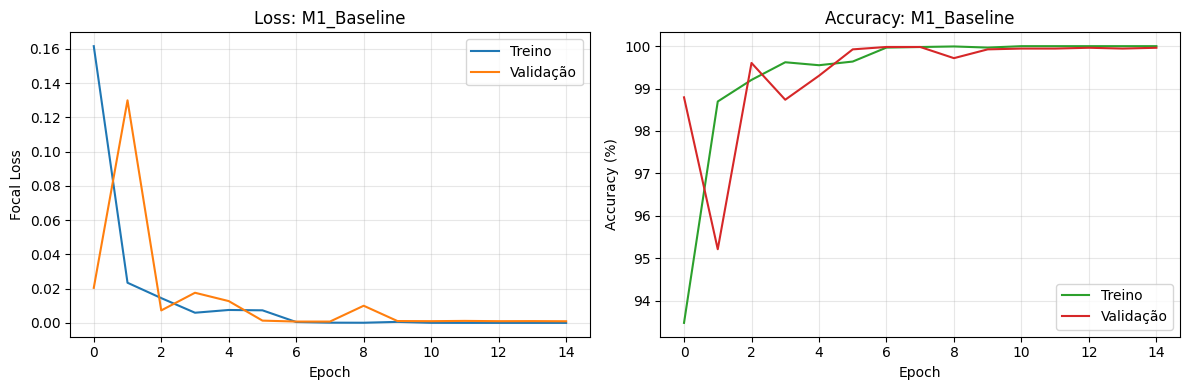

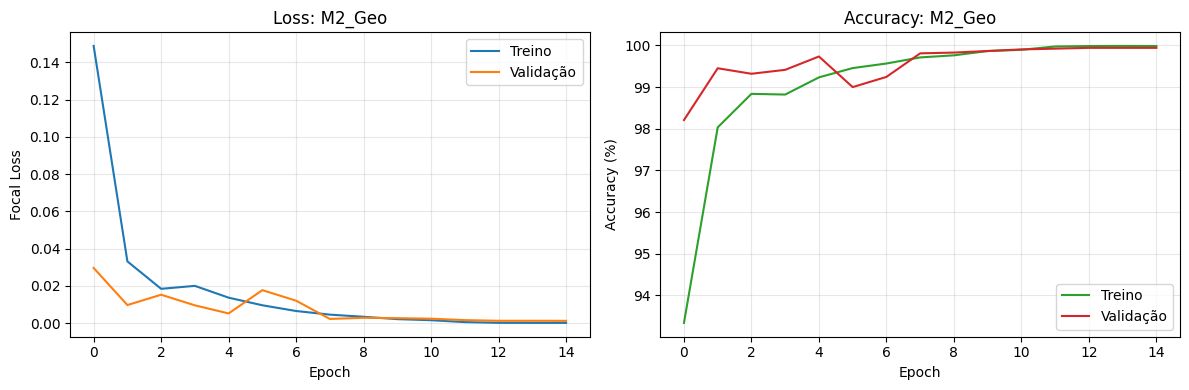

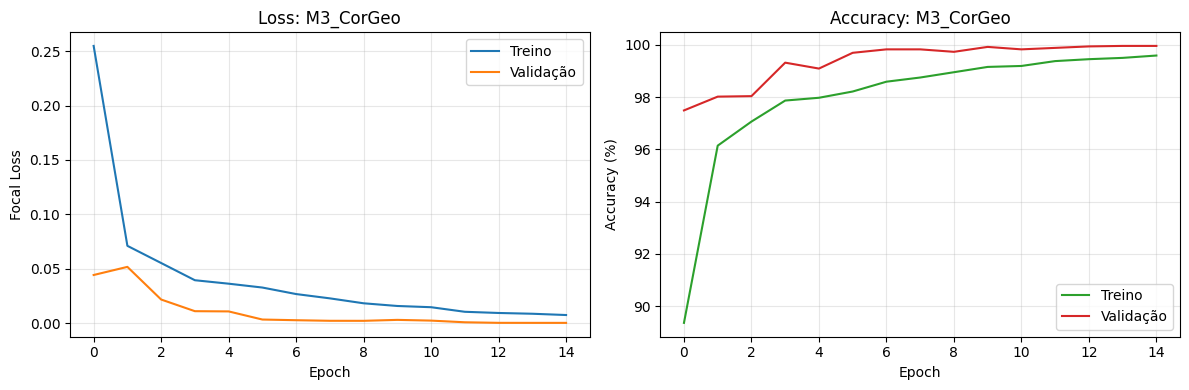

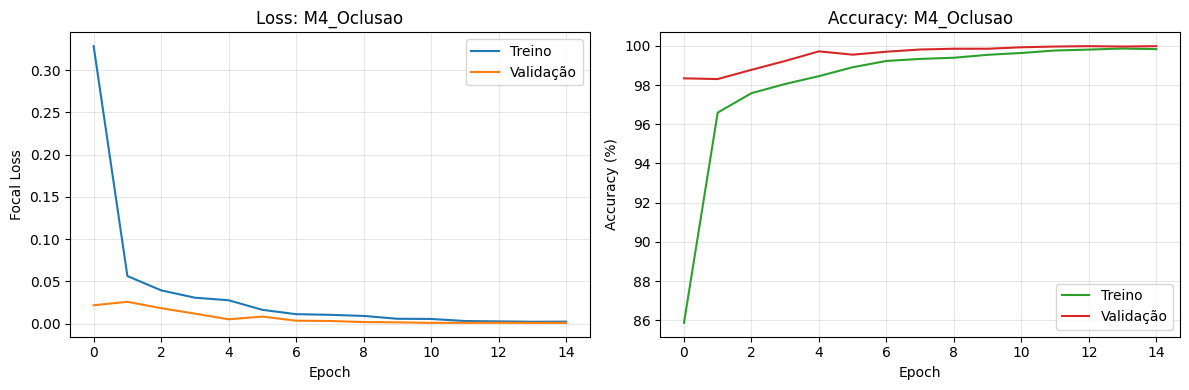

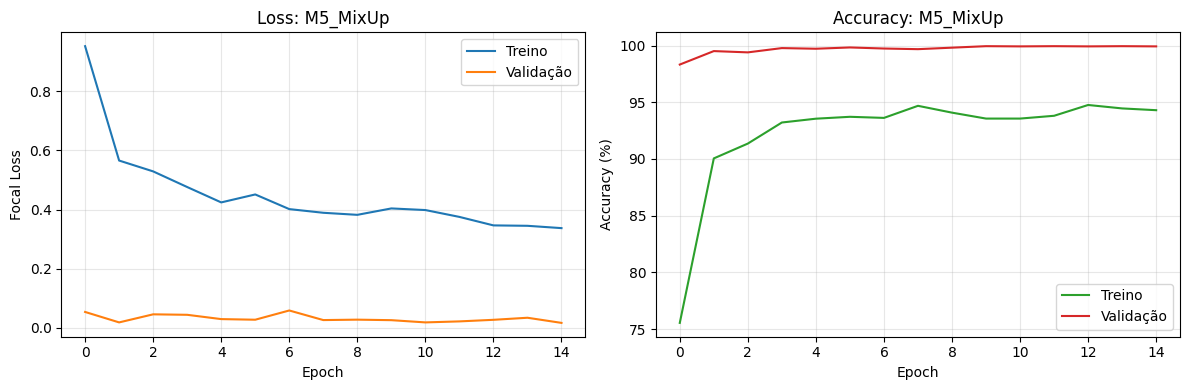

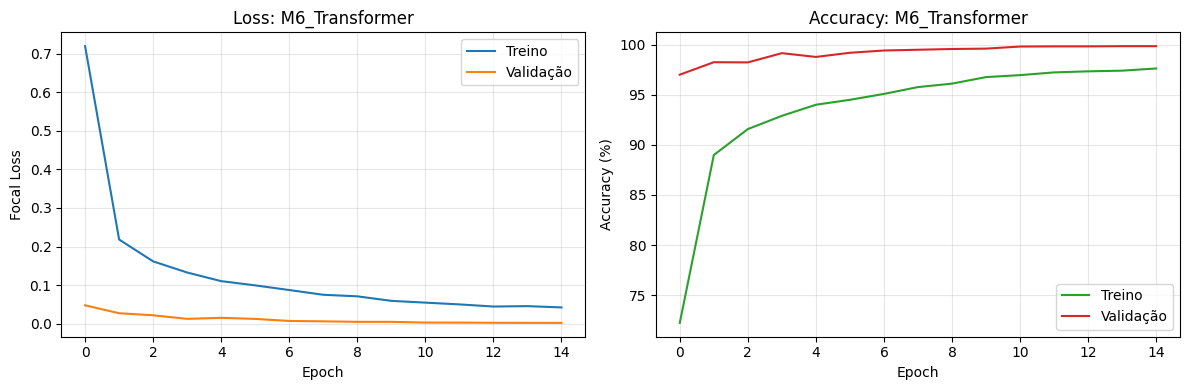

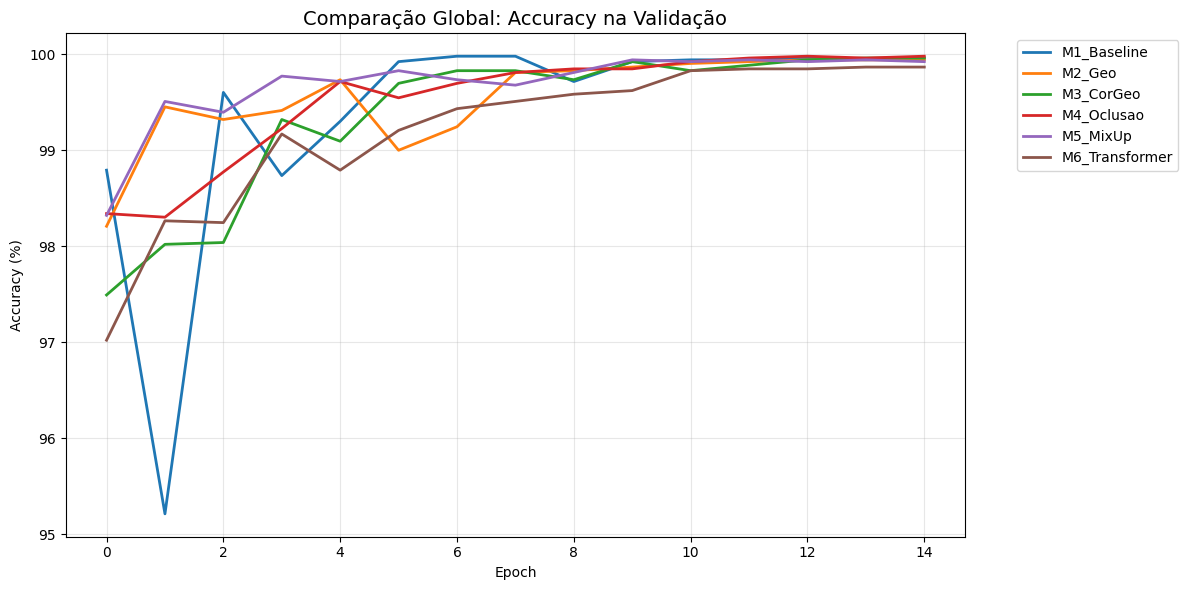

In [ ]:
# ==========================================
# =   VISUALIZAÇÃO DE RESULTADOS TOTAIS    =
# ==========================================
import matplotlib.pyplot as plt

def plot_model_history(model_name, history):
    plt.figure(figsize=(12, 4))
    
    # Gráfico de Loss
    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label='Treino', color='#1f77b4')
    plt.plot(history['val_loss'], label='Validação', color='#ff7f0e')
    plt.title(f'Loss: {model_name}')
    plt.xlabel('Epoch')
    plt.ylabel('Focal Loss')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Gráfico de Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(history['train_acc'], label='Treino', color='#2ca02c')
    plt.plot(history['val_acc'], label='Validação', color='#d62728')
    plt.title(f'Accuracy: {model_name}')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# Gerar gráficos para todos os modelos que treinaram
print("\n=== GALERIA DE RESULTADOS FINAIS ===")
for name, hist in history_all.items():
    plot_model_history(name, hist)

# Gráfico Comparativo Final (Apenas Accuracy de Validação)
plt.figure(figsize=(12, 6))
for name, hist in history_all.items():
    plt.plot(hist['val_acc'], label=name, linewidth=2)

plt.title('Comparação Global: Accuracy na Validação', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()